EDA Assignment: Does More Health Spending = Longer Life?
**Name:** ___________________  |  **Date:** __________  |  ⏱️ *Target time: ~1 hour*

---
### 🤔 The big question
Every country spends money on healthcare — some spend *a lot* more than others. It seems obvious that **spending more should mean people live longer**... right?

**Your job:** use EDA to find out if that's actually true. This is an **open-ended** assignment — there's no single "correct" cell to fill in. You explore the data, follow what's interesting, and back up your answer with charts.

> 🎯 **Before you touch the data, write your gut guess here:**
> *Do you think the country that spends the MOST on healthcare also lives the longest? (yes / no / not sure):* __________

**The dataset:** health spending per person vs life expectancy, for 6 wealthy countries, 1970–2020 (real OECD-style data, built into seaborn — loads offline).

### 📤 What to hand in
Answer every ✍️ **question** in your own words, and make sure your charts are clear (titles + labels). Marks reward **insight and evidence**, not fancy code. Run *Kernel → Restart & Run All* before submitting.

## Step 0 — Setup & Load *(warm-up)*

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_theme(style='whitegrid')

df = sns.load_dataset('healthexp')   # Year, Country, Spending_USD, Life_Expectancy
print("Shape:", df.shape)
df.head()

Shape: (274, 4)


,Year,Country,Spending_USD,Life_Expectancy
0,1970,Germany,252.311,70.6
1,1970,France,192.143,72.2
2,1970,Great Britain,123.993,71.9
3,1970,Japan,150.437,72.0
4,1970,USA,326.961,70.9


In [2]:
print('Countries:', df['Country'].unique())
print('Year range:', df['Year'].min(), 'to', df['Year'].max())
display(df.describe(include='all'))


Countries: ['Germany' 'France' 'Great Britain' 'Japan' 'USA' 'Canada']
Year range: 1970 to 2020


,Year,Country,Spending_USD,Life_Expectancy
count,274.000000,274,274.000000,274.000000
unique,NaN,6,NaN,NaN
top,NaN,USA,NaN,NaN
freq,NaN,51,NaN,NaN
mean,1996.992701,NaN,2789.338905,77.909489
std,14.180933,NaN,2194.939785,3.276263
min,1970.000000,NaN,123.993000,70.600000
25%,1985.250000,NaN,1038.357000,75.525000
50%,1998.000000,NaN,2295.578000,78.100000
75%,2009.000000,NaN,4055.610000,80.575000


## Task 1 — The Core Relationship *(≈15 min)*
*Is there a link between how much a country spends and how long people live?*

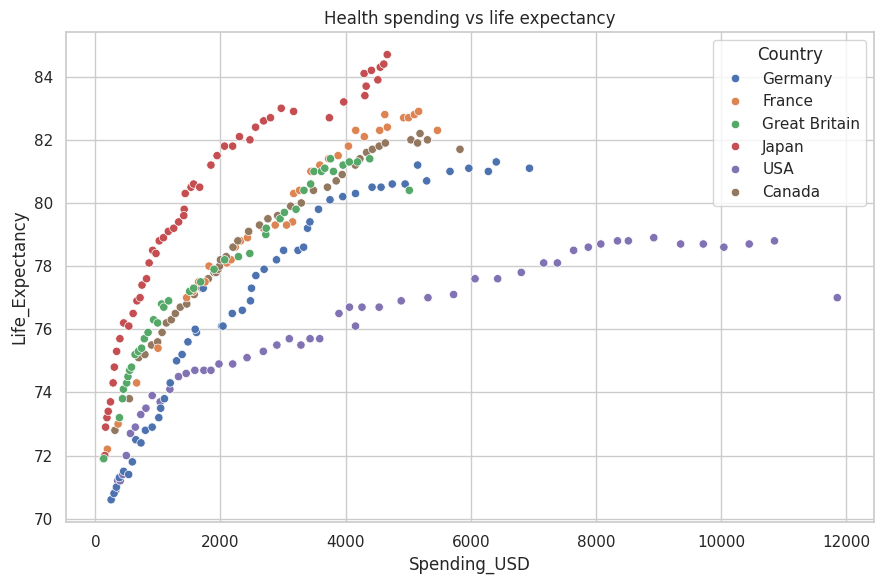

In [3]:
plt.figure(figsize=(9,6)); sns.scatterplot(data=df,x='Spending_USD',y='Life_Expectancy',hue='Country'); plt.title('Health spending vs life expectancy'); plt.tight_layout(); plt.show()


**✍️ Q1:** In general, as spending goes up, does life expectancy go up, down, or stay flat? Would you call the relationship strong or weak?
*Your answer:* _______________

*Optional hint for evidence:* `df['Spending_USD'].corr(df['Life_Expectancy'])` gives a number from −1 to +1.

## Task 2 — Find the Odd One Out *(≈15 min)*
*Every good analyst looks for what breaks the pattern.*

,Country,Year,Spending_USD,Life_Expectancy
273,USA,2020,11859.179,77.0
269,Germany,2020,6938.983,81.1
268,Canada,2020,5828.324,81.7
270,France,2020,5468.418,82.3
271,Great Britain,2020,5018.700,80.4
272,Japan,2020,4665.641,84.7


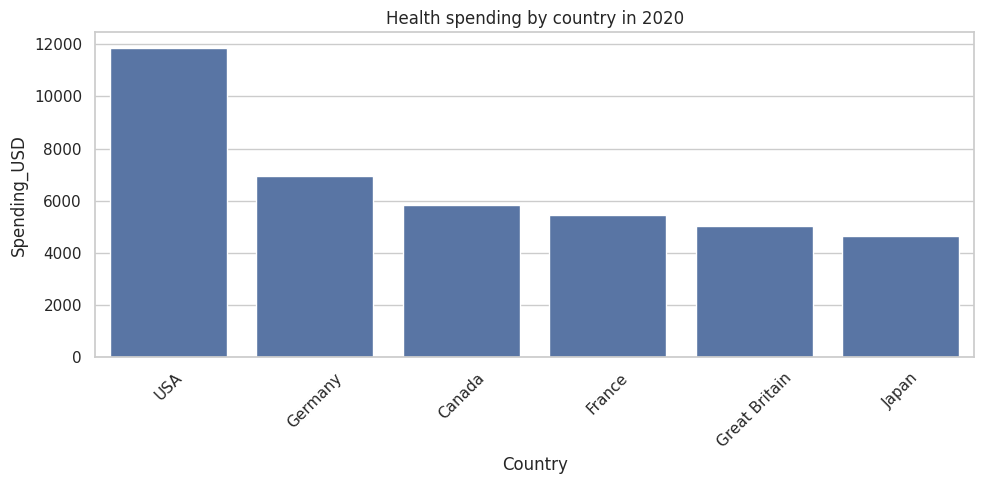

In [4]:
latest=df[df['Year']==df['Year'].max()].sort_values('Spending_USD',ascending=False)
display(latest[['Country','Year','Spending_USD','Life_Expectancy']])
plt.figure(figsize=(10,5)); sns.barplot(data=latest,x='Country',y='Spending_USD'); plt.title(f'Health spending by country in {df.Year.max()}'); plt.xticks(rotation=45); plt.tight_layout(); plt.show()


**✍️ Q2:** Which country **spends the most** per person? Which country **lives the longest**? Are they the same country? *(This is the heart of the assignment — what surprised you?)*
*Your answer:* _______________

## Task 3 — Change Over Time *(≈15 min)*
*Has the story always been this way, or did it change?*

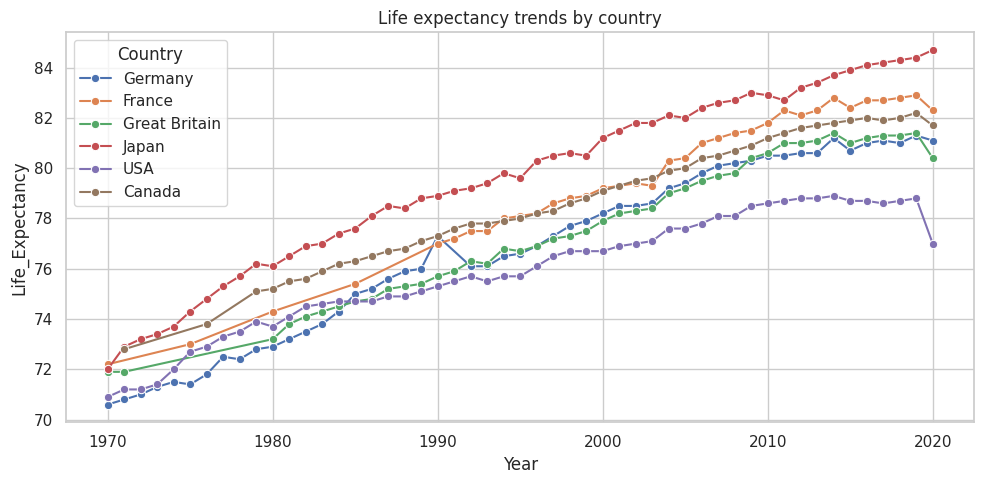

In [5]:
plt.figure(figsize=(10,5)); sns.lineplot(data=df,x='Year',y='Life_Expectancy',hue='Country',marker='o'); plt.title('Life expectancy trends by country'); plt.tight_layout(); plt.show()


**✍️ Q3:** Describe one clear trend you see over time. Does one country pull away from the others at some point?
*Your answer:* _______________

## Task 4 — Your Own Investigation *(≈10 min)*  🔍 *open-ended*
Ask **your own** question about this data and answer it with **one** chart. Ideas (or invent your own):
- Who improved their life expectancy the *most* since 1970?
- Which country gets the most "life expectancy per dollar" (best value)?
- Is any country's life expectancy *flattening* even as spending climbs?

Country
Japan            12.7
Germany          10.5
France           10.1
Canada            8.9
Great Britain     8.5
USA               6.1
Name: Life_Expectancy, dtype: float64


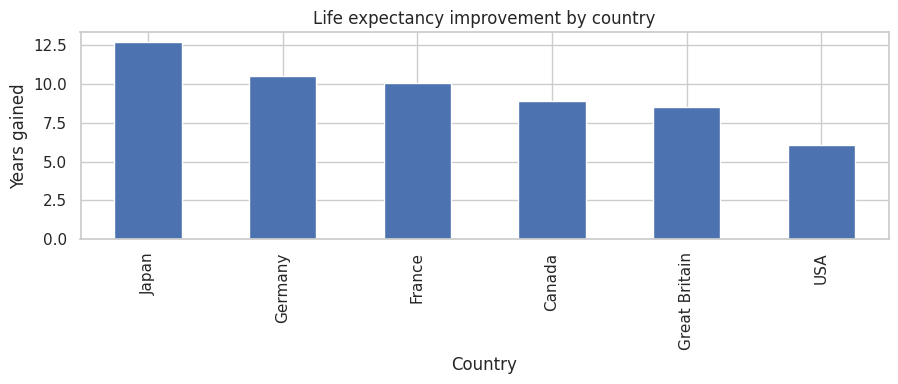

In [6]:
# Question: Which country had the largest improvement in life expectancy over the observed period?
first=df.sort_values('Year').groupby('Country').first()['Life_Expectancy']; last=df.sort_values('Year').groupby('Country').last()['Life_Expectancy']; improvement=(last-first).sort_values(ascending=False); print(improvement)
improvement.plot(kind='bar',figsize=(9,4),title='Life expectancy improvement by country'); plt.ylabel('Years gained'); plt.tight_layout(); plt.show()


**✍️ Q4:** What did *your* chart show? State your finding in one sentence.
*Your answer:* _______________

## 🏁 Your Verdict
Answer the assignment's big question in **2–3 sentences**, using what your charts showed. Then look back: **was your gut guess from the top right or wrong?**

**✍️ Final verdict:**

> _______________________________________________
>
> _______________________________________________

> *My original guess was (right / wrong) because: _______________*

---
✅ *Before submitting:* every ✍️ answered, charts have titles/labels, ran Restart & Run All with no errors. Nice work! 🎉